# 03 - Özellik Çıkarımı: LBP + GLCM

Her 256×256 görüntüden iki tür doku özelliği çıkarıyoruz:

| Yöntem | Ayar | Boyut |
|---|---|---|
| **LBP** (Yerel İkili Örüntüler) | P=8, R=1, `nri_uniform` | 59 |
| **GLCM** (Gri Seviye Eş Oluşum Matrisi) | d=1; 0°, 45°, 90°, 135°; 6 özellik | 24 |
| **Toplam** | | **83** |

Önce `02` notebook'u çalıştırılmış ve `data/processed/images_256/` klasörü dolu olmalı.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config
from src import features as F
from src.preprocess import read_gray, PROCESSED_IMG_DIR
sns.set_theme(style="whitegrid")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

idx = pd.read_csv(PROCESSED_IMG_DIR / "index.csv")
print(len(idx), "görüntü,", idx["family"].nunique(), "aile")

9339 görüntü, 25 aile


## 1. LBP: tek görüntü üzerinde

LBP her pikseli 8 komşusuyla karşılaştırır. Komşu merkezden büyük ya da eşitse 1, küçükse 0 yazılır. Çıkan 8 bitlik örüntü pikselin kodu olur. `nri_uniform` yönteminde en fazla 2 geçiş (0→1 veya 1→0) içeren 58 "düzgün" örüntü ayrı ayrı sayılır. Geri kalan bütün örüntüler tek bir kutuda toplanır, böylece 59 kutu elde edilir.

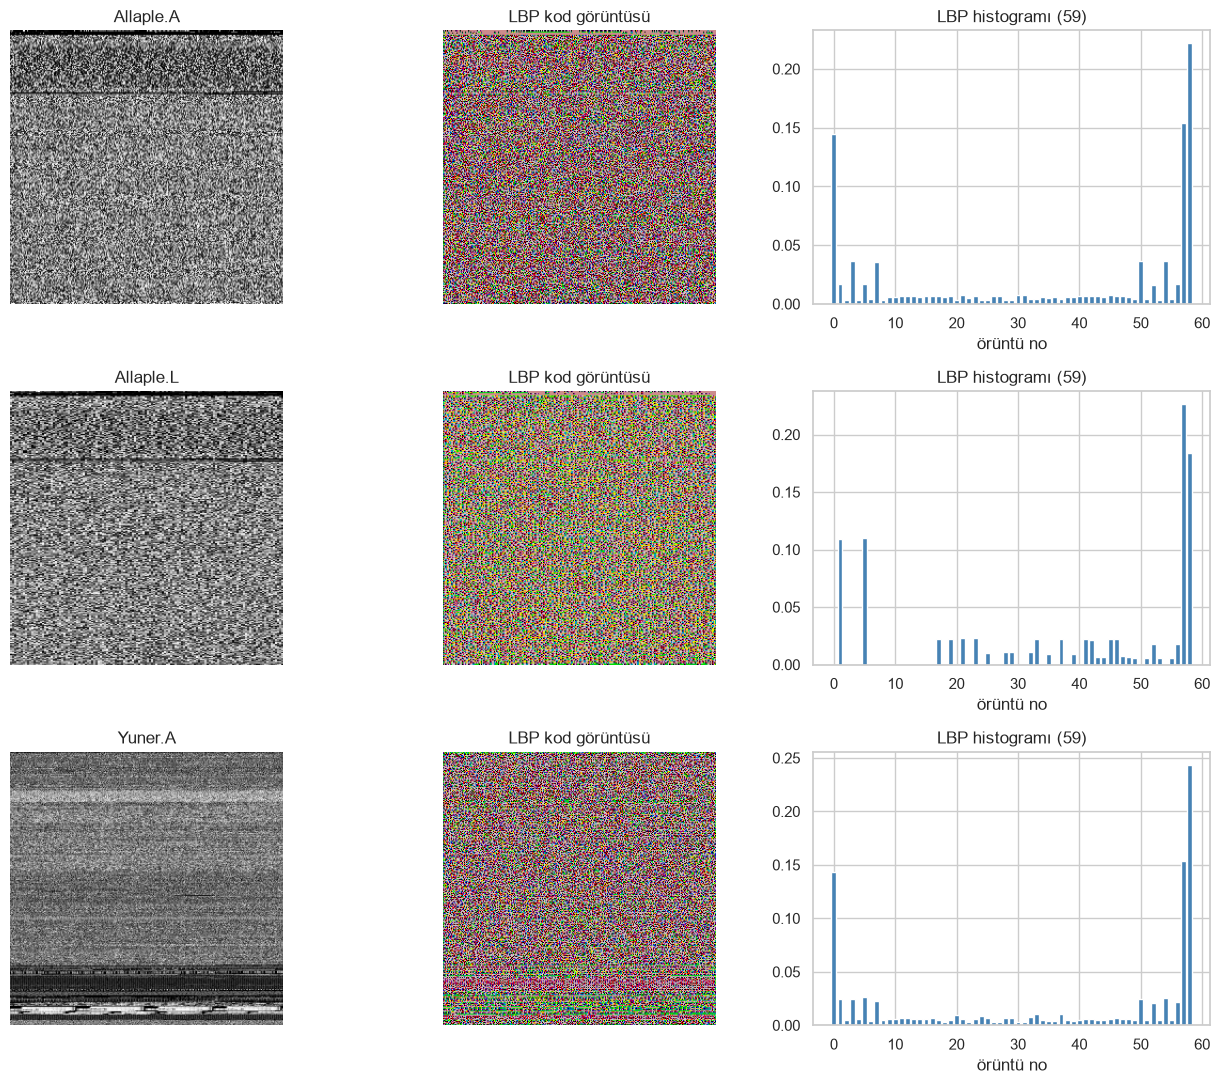

In [2]:
ornek_aileler = idx["family"].value_counts().index[:3].tolist()
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for i, fam in enumerate(ornek_aileler):
    img = read_gray(idx[idx["family"] == fam]["path"].iloc[0])
    axes[i, 0].imshow(img, cmap="gray"); axes[i, 0].set_title(f"{fam}"); axes[i, 0].axis("off")
    axes[i, 1].imshow(F.lbp_image(img), cmap="nipy_spectral"); axes[i, 1].set_title("LBP kod görüntüsü"); axes[i, 1].axis("off")
    axes[i, 2].bar(range(F.N_LBP_BINS), F.lbp_features(img), color="steelblue")
    axes[i, 2].set_title("LBP histogramı (59)"); axes[i, 2].set_xlabel("örüntü no")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "03_lbp_ornek.png", dpi=150)
plt.show()

## 2. GLCM: tek görüntü üzerinde

GLCM, belirli bir yönde yan yana duran iki pikselin (i, j) gri değer çiftinin ne sıklıkla görüldüğünü sayar. Bu matristen 6 özellik hesaplanır: kontrast, farklılık, homojenlik, enerji, korelasyon ve ASM. Her biri 4 açı için ayrı ayrı hesaplandığından 24 değer çıkar.

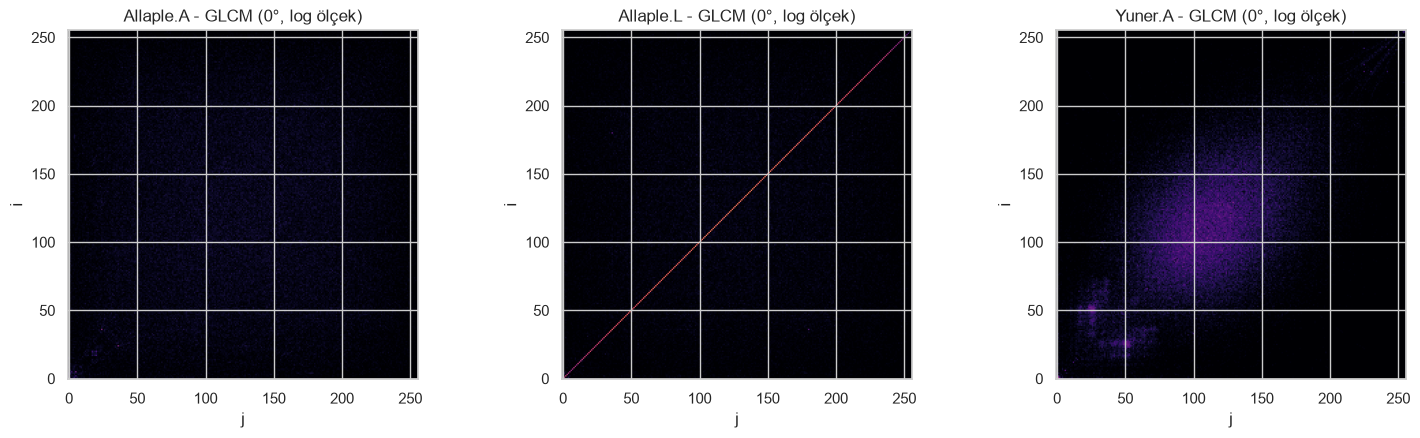

,0°,45°,90°,135°
contrast,2407.7821,3031.9921,2746.5168,2907.0345
dissimilarity,35.8895,41.1389,39.0504,40.0687
homogeneity,0.0764,0.0571,0.0619,0.0569
energy,0.0377,0.0289,0.0311,0.0289
correlation,0.4741,0.3359,0.3983,0.3633
ASM,0.0014,0.0008,0.0010,0.0008


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, fam in zip(axes, ornek_aileler):
    img = read_gray(idx[idx["family"] == fam]["path"].iloc[0])
    m = F.glcm_matrix(img)[:, :, 0, 0]           # d=1, 0°
    ax.imshow(np.log1p(m * 1e4), cmap="magma", origin="lower")
    ax.set_title(f"{fam} - GLCM (0°, log ölçek)"); ax.set_xlabel("j"); ax.set_ylabel("i")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "03_glcm_ornek.png", dpi=150)
plt.show()

img = read_gray(idx["path"].iloc[0])
g = pd.Series(F.glcm_features(img), index=F.glcm_feature_names())
pd.DataFrame(g.values.reshape(len(config.GLCM_PROPS), -1),
             index=config.GLCM_PROPS, columns=[f"{a}°" for a in config.GLCM_ANGLES_DEG]).round(4)

## 3. Tüm veri seti için özellik çıkarımı

Bir görüntü yaklaşık 50 ms sürüyor, tek çekirdekte 9.339 görüntü 8 dakika civarında tamamlanır. `n_jobs=-1` ile bilgisayarın bütün çekirdekleri kullanılır.

> Windows'ta `n_jobs=-1` notebook içinde sorun çıkarırsa terminalden `python -m src.features --n-jobs -1` komutunu çalıştırın.

In [4]:
feats = F.extract_dataset(n_jobs=-1)
feats.head()

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:    3.8s
[Parallel(n_jobs=-1)]: Done  56 tasks      | elapsed:    5.2s
[Parallel(n_jobs=-1)]: Done 146 tasks      | elapsed:    7.1s
[Parallel(n_jobs=-1)]: Done 272 tasks      | elapsed:    9.8s
[Parallel(n_jobs=-1)]: Done 434 tasks      | elapsed:   13.5s
[Parallel(n_jobs=-1)]: Done 632 tasks      | elapsed:   18.0s
[Parallel(n_jobs=-1)]: Done 866 tasks      | elapsed:   23.1s
[Parallel(n_jobs=-1)]: Done 1136 tasks      | elapsed:   28.4s
[Parallel(n_jobs=-1)]: Done 1442 tasks      | elapsed:   35.0s
[Parallel(n_jobs=-1)]: Done 1784 tasks      | elapsed:   41.6s
[Parallel(n_jobs=-1)]: Done 2162 tasks      | elapsed:   48.6s
[Parallel(n_jobs=-1)]: Done 2576 tasks      | elapsed:   56.9s
[Parallel(n_jobs=-1)]: Done 3026 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 3512 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done 4034 tasks      | ela

9339 görüntü, 83 özellik, 197.5 sn -> C:\Users\Asus\OneDrive\Masaüstü\BP\malware-image-classification\data\processed\features.csv


,path,family,label_id,lbp_0,lbp_1,lbp_2,lbp_3,lbp_4,lbp_5,lbp_6,...,glcm_energy_1_90,glcm_energy_1_135,glcm_correlation_1_0,glcm_correlation_1_45,glcm_correlation_1_90,glcm_correlation_1_135,glcm_ASM_1_0,glcm_ASM_1_45,glcm_ASM_1_90,glcm_ASM_1_135
0,C:\Users\Asus\OneDrive\Masaüstü\BP\malware-ima...,Adialer.C,0,0.143738,0.022614,0.004425,0.025406,0.004868,0.021317,0.004456,...,0.031105,0.028902,0.474062,0.335864,0.398348,0.363270,0.001423,0.000833,0.000968,0.000835
1,C:\Users\Asus\OneDrive\Masaüstü\BP\malware-ima...,Adialer.C,0,0.144699,0.022339,0.004166,0.026001,0.004837,0.021515,0.004456,...,0.035516,0.033281,0.468688,0.361103,0.425208,0.390321,0.001904,0.001107,0.001261,0.001108
2,C:\Users\Asus\OneDrive\Masaüstü\BP\malware-ima...,Adialer.C,0,0.144058,0.022324,0.003967,0.026108,0.004501,0.022110,0.004425,...,0.030801,0.028523,0.475120,0.337700,0.400167,0.364387,0.001394,0.000810,0.000949,0.000814
3,C:\Users\Asus\OneDrive\Masaüstü\BP\malware-ima...,Adialer.C,0,0.144379,0.022873,0.004196,0.025543,0.004913,0.021606,0.004745,...,0.036092,0.033796,0.471045,0.363712,0.426147,0.392912,0.001950,0.001142,0.001303,0.001142
4,C:\Users\Asus\OneDrive\Masaüstü\BP\malware-ima...,Adialer.C,0,0.144699,0.022339,0.004166,0.026001,0.004837,0.021515,0.004456,...,0.035516,0.033281,0.468688,0.361103,0.425208,0.390321,0.001904,0.001107,0.001261,0.001108


In [5]:
X, y, meta = F.load_features()
print("X:", X.shape, "| y:", y.shape)
print("Eksik değer:", int(X.isna().sum().sum()), "| Sonsuz değer:", int(np.isinf(X.values).sum()))
X.describe().T.head(10)

X: (9339, 83) | y: (9339,)
Eksik değer: 0 | Sonsuz değer: 0


,count,mean,std,min,25%,50%,75%,max
lbp_0,9339.0,0.103684,0.064531,0.000000,0.016830,0.143082,0.148682,0.178467
lbp_1,9339.0,0.038361,0.033443,0.003891,0.018364,0.022385,0.042618,0.111374
lbp_2,9339.0,0.003171,0.002070,0.000000,0.000198,0.003998,0.004761,0.006226
lbp_3,9339.0,0.020567,0.014017,0.000000,0.000687,0.024200,0.033073,0.042419
lbp_4,9339.0,0.003173,0.002076,0.000000,0.000336,0.003906,0.004715,0.006195
lbp_5,9339.0,0.038636,0.033654,0.002686,0.018661,0.022430,0.042130,0.112045
lbp_6,9339.0,0.003048,0.001968,0.000000,0.000214,0.003906,0.004288,0.006256
lbp_7,9339.0,0.020030,0.013660,0.000000,0.000702,0.022812,0.030716,0.043060
lbp_8,9339.0,0.003093,0.001986,0.000000,0.000275,0.003983,0.004623,0.006165
lbp_9,9339.0,0.004447,0.002725,0.000000,0.000778,0.005585,0.006088,0.011505


## 4. Özellikler aileleri ayırt ediyor mu?

Bir özelliğin aile ortalamaları birbirinden belirgin şekilde farklıysa, o özellik sınıflandırmada işe yarayacak demektir.

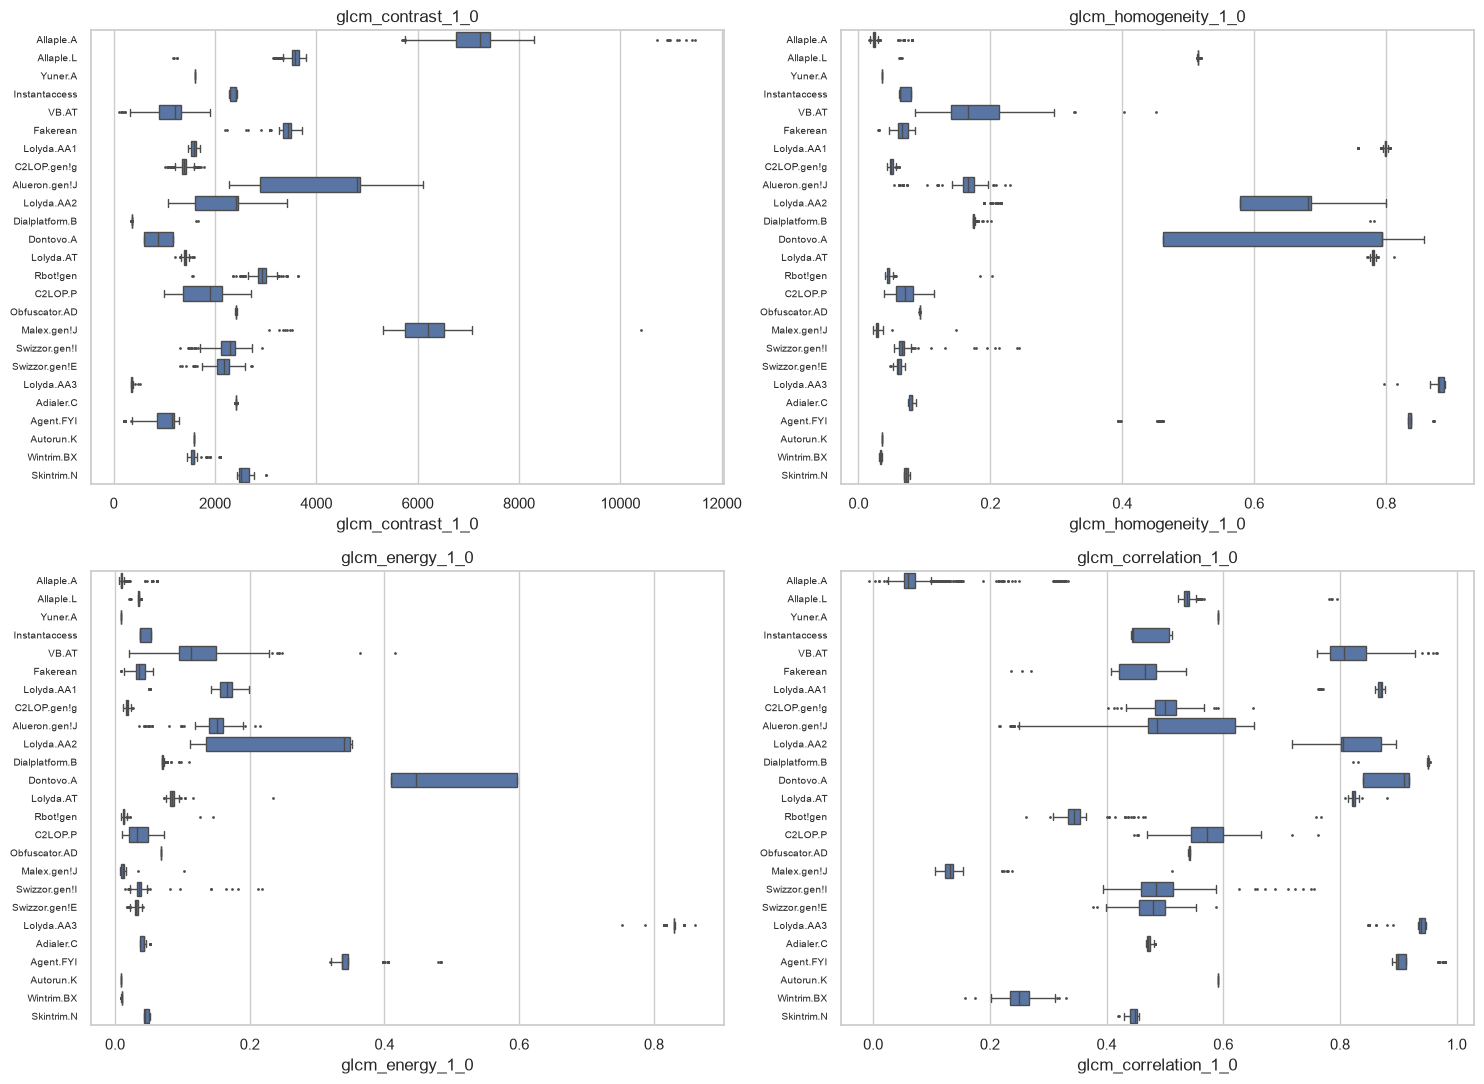

In [6]:
secili = ["glcm_contrast_1_0", "glcm_homogeneity_1_0", "glcm_energy_1_0", "glcm_correlation_1_0"]
sira = y.value_counts().index
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, col in zip(axes.flat, secili):
    sns.boxplot(x=X[col], y=y, order=sira, ax=ax, fliersize=1)
    ax.set_title(col); ax.set_ylabel(""); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "03_glcm_aile_kutu.png", dpi=150)
plt.show()

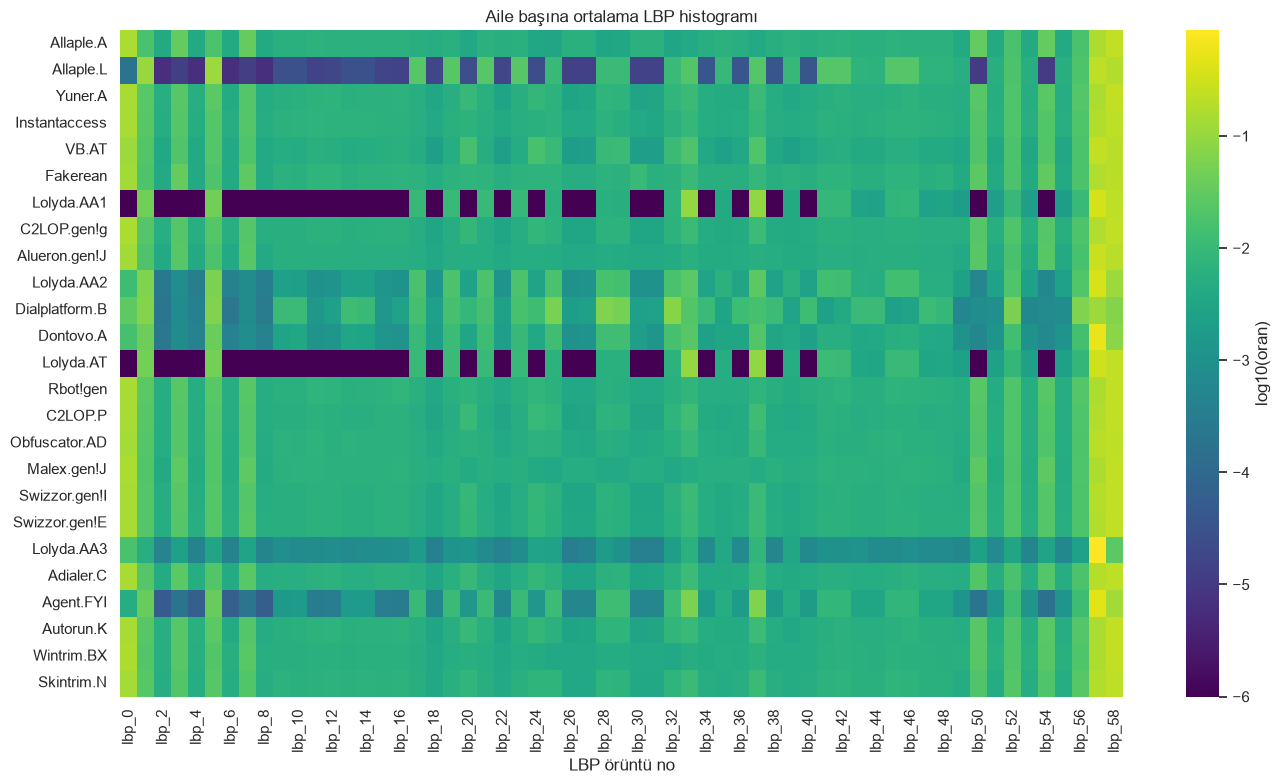

In [7]:
# Aile başına ortalama LBP histogramı (ısı haritası)
lbp_cols = F.lbp_feature_names()
ort = X[lbp_cols].groupby(y).mean().loc[sira]
fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(np.log10(ort + 1e-6), cmap="viridis", ax=ax, cbar_kws={"label": "log10(oran)"})
ax.set_xlabel("LBP örüntü no"); ax.set_ylabel("")
ax.set_title("Aile başına ortalama LBP histogramı")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "03_lbp_aile_isi.png", dpi=150)
plt.show()

## 5. GLCM özellikleri arasındaki korelasyon

Çok yüksek korelasyonlu (|r| > 0.95) özellikler aynı bilgiyi taşır. Bunu raporda belirtmek, 5. haftadaki modellerin sonuçlarını yorumlarken işe yarar.

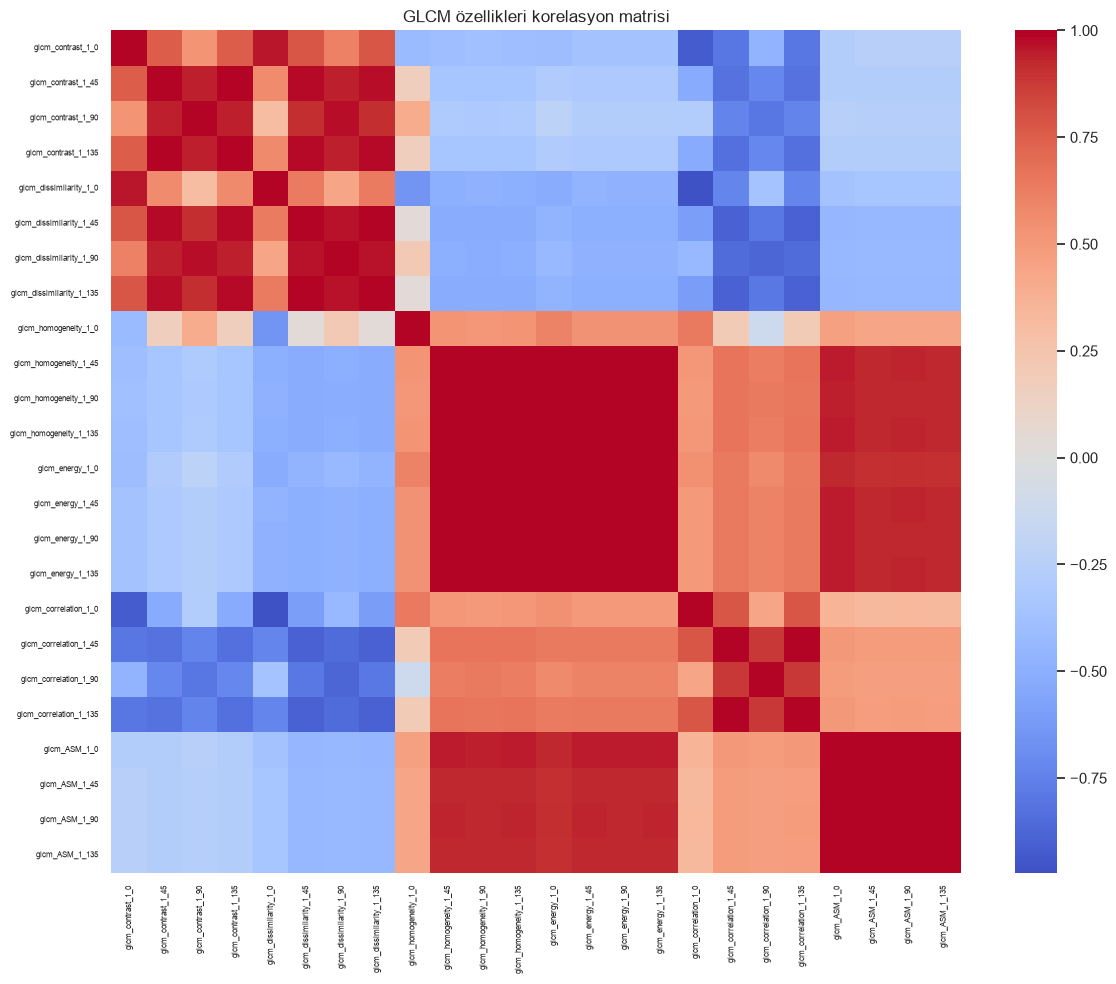

|r| > 0.95 olan çift sayısı: 39


,özellik 1,özellik 2,r
0,glcm_contrast_1_0,glcm_dissimilarity_1_0,0.957
1,glcm_contrast_1_45,glcm_contrast_1_135,1.000
2,glcm_contrast_1_45,glcm_dissimilarity_1_45,0.977
3,glcm_contrast_1_45,glcm_dissimilarity_1_135,0.977
4,glcm_contrast_1_90,glcm_dissimilarity_1_90,0.970
5,glcm_contrast_1_135,glcm_dissimilarity_1_45,0.977
6,glcm_contrast_1_135,glcm_dissimilarity_1_135,0.977
7,glcm_dissimilarity_1_0,glcm_correlation_1_0,-0.972
8,glcm_dissimilarity_1_45,glcm_dissimilarity_1_90,0.963
9,glcm_dissimilarity_1_45,glcm_dissimilarity_1_135,1.000


In [8]:
glcm_cols = F.glcm_feature_names()
corr = X[glcm_cols].corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, xticklabels=True, yticklabels=True)
ax.tick_params(labelsize=6)
ax.set_title("GLCM özellikleri korelasyon matrisi")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "03_glcm_korelasyon.png", dpi=150)
plt.show()

yuksek = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(glcm_cols)
          for b in glcm_cols[i + 1:] if abs(corr.loc[a, b]) > 0.95]
print(f"|r| > 0.95 olan çift sayısı: {len(yuksek)}")
pd.DataFrame(yuksek, columns=["özellik 1", "özellik 2", "r"]).head(15)

## 6. Notlar

- Özellik çıkarımı süresi (tek çekirdek / paralel):
- Aileleri en iyi ayırıyor gibi görünen GLCM özellikleri:
- LBP ısı haritasında birbirine çok benzeyen aileler:
- Yüksek korelasyonlu özellik grupları: